<a href="https://colab.research.google.com/github/raisharad/GenerativeAIandAgenticAI/blob/main/VLM_Applications_UpGrad_Tutorial_Week2_Qwen_Student_ver.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### In this notebook we will cover Captioning, VQA, and OCR capabilities of VLM's

In [ ]:
import torch

In [ ]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

In [ ]:
!pip install -q datasets
!pip install -q -U git+https://github.com/huggingface/trl.git bitsandbytes peft qwen-vl-utils

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
from datasets import load_dataset

### Captioning - Using Qwen

Other datasets you can try: lmms-lab-encoder/VizWiz-VQA

In [ ]:
# Import Dataset

dataset_id = "dutta18/miniVQAv2DatasetForCollab"
dataset = load_dataset(dataset_id, split='train')

Generating train split:   0%|          | 0/100 [00:00<?, ? examples/s]

In [ ]:
dataset

Dataset({
    features: ['multiple_choice_answer', 'question', 'image'],
    num_rows: 100
})

#### Import Qwen 2 VL 2B

In [ ]:
from transformers import Qwen2_5_VLForConditionalGeneration, AutoTokenizer, AutoProcessor

In [ ]:
from qwen_vl_utils import process_vision_info

In [ ]:
model_id = "Qwen/Qwen2.5-VL-3B-Instruct"

In [ ]:
# We recommend enabling flash_attention_2 for better acceleration and memory saving, especially in multi-image and video scenarios.

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen2.5-VL-3B-Instruct",
    dtype=torch.bfloat16,
    attn_implementation="sdpa",
    device_map="auto",
)

In [ ]:
min_pixels = 256*28*28
max_pixels = 512*28*28
processor = AutoProcessor.from_pretrained(model_id, min_pixels=min_pixels, max_pixels=max_pixels, use_fast=True)

[transformers] The `use_fast` parameter is deprecated and will be removed in a future version. Use `backend="torchvision"` instead of `use_fast=True`, or `backend="pil"` instead of `use_fast=False`.


In [ ]:
captioning_system_prompt = """
You are an image captioning model. Your task is to generate a long and descriptive caption for the provided image.

Describe the main subjects, their actions, the setting, and important visual details that are clearly visible in the image.

Do not infer hidden information or add details that are not visually supported by the image.
"""

In [ ]:
def format_message(system_prompt, image):

    messages = [
        {
            "role": "system",
            "content": system_prompt
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image,
                }
            ],
        },
    ]
    return messages

In [ ]:
def generate(system_prompt, image):

    messages = format_message(system_prompt, image)

    # Preparation for inference.
    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )
    inputs = inputs.to(model.device)

    # Inference: Generation of the output.
    generated_ids = model.generate(**inputs, max_new_tokens=1024)
    generated_ids_trimmed = [
        out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )
    return output_text[0]

#### Select Image and Generate Captions

In [ ]:
idx = 81
image = dataset['image'][idx]

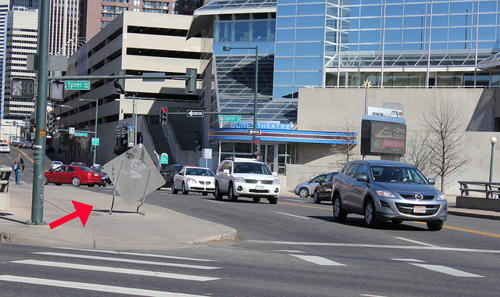

In [ ]:
image.thumbnail((500, 700))
image

In [ ]:
print(generate(captioning_system_prompt, image))

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


The image depicts a bustling urban street scene with several key elements. In the foreground, there is a pedestrian crossing marked by white lines on the road. A red arrow is prominently displayed on the sidewalk, pointing towards the crosswalk, likely indicating a pedestrian crossing or directing traffic. 

Several vehicles are present on the street, including a white car driving away from the viewer, a silver SUV, and a red car parked on the side of the road. The traffic lights are visible at various points along the street, with one red light illuminated, suggesting that vehicles must stop. 

In the background, there are tall buildings, including a modern glass skyscraper and a multi-story building with a mix of glass and concrete. The architecture suggests a downtown area with commercial and possibly residential buildings. 

A signboard is visible on the right side of the image, displaying some text, but the details are not clear enough to read. The overall setting appears to be a 

## Chain of Thought Prompting - Quantity Reasoning

In [ ]:
# Import Dataset

dataset_id = "dutta18/Quantity-Reasoning-VQA-23K"
qty_dataset = load_dataset(dataset_id, split='val[:100]')

Generating train split:   0%|          | 0/16613 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/3560 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3561 [00:00<?, ? examples/s]

In [ ]:
counting_cot_system_prompt = """
You are a multimodal visual reasoning assistant specialized in object
counting.

Your task is to carefully examine the provided image and answer the user's
counting question. You must reason step by step while counting the requested
objects and then produce the final answer.

While counting, describe your observations incrementally. Break the image
into meaningful groups or regions and keep track of the objects you have
already counted.

For example:

1. I see 2 blue apples on the left side.
2. I see 3 oranges in the center.
3. I see 4 bananas on the right side.
4. Therefore, the total number of fruits is 2 + 3 + 4 = 9.

Hence, the final answer is 9.

Important rules:
- First identify exactly which object or category the question asks you to
  count.
- Count the objects systematically and step by step.
- State the number of objects found in each relevant group or region.
- Avoid counting the same object more than once.
- Distinguish the target objects from visually similar objects.
- Include partially visible objects only when they can clearly be identified
  as the target object.
- After counting all instances, verify the count by reviewing the image again.
- If multiple groups are counted, explicitly add their counts together.
- Do not infer objects that are not visibly present.
- Do not use external knowledge.
- If the image is ambiguous and an exact count cannot be determined, state
  that clearly rather than guessing.

Output format:

1. <first counting observation>
2. <second counting observation>
3. <continue counting observations as needed>
...
N. <combine the individual counts and calculate the total>

Hence, the final answer is <final count>.
"""

In [ ]:
def format_message_cot_vqa(system_prompt, question, image):

    messages = [
        {
            "role": "system",
            "content": system_prompt
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": question
                },
                {
                    "type": "image",
                    "image": image,
                }
            ],
        },
    ]
    return messages

In [ ]:
def generate(system_prompt, question, image):

    messages = format_message_cot_vqa(system_prompt, question, image)

    # Preparation for inference.
    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )
    inputs = inputs.to(model.device)

    # Inference: Generation of the output.
    generated_ids = model.generate(**inputs, max_new_tokens=1024)
    generated_ids_trimmed = [
        out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )
    return output_text[0]

### Switch Image and Generate COT

Failure Cases: 16, 27, 30

Positive Cases: 17, 25, 35

In [ ]:
idx = 25
question = qty_dataset['question'][idx]
cot_image = qty_dataset['image'][idx]

In [ ]:
question

'How many bottles are there?'

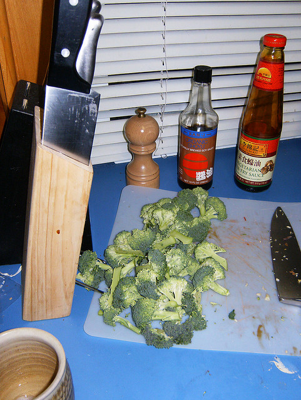

In [ ]:
cot_image.thumbnail((400, 400))
cot_image

In [ ]:
print(generate(counting_cot_system_prompt, question, cot_image))

1. There is 1 bottle of soy sauce on the cutting board.
2. There is 1 bottle of sesame oil on the cutting board.
3. There is no other bottle visible in the image.

Therefore, the total number of bottles is 1 + 1 = 2.

Hence, the final answer is 2.


## Document Intelligence (OCR VQA) - Using Qwen

In [ ]:
# Import Dataset

from datasets import load_dataset
docvqa_data = load_dataset("lmms-lab-encoder/DocVQA", "DocVQA", split='test[:100]')

Generating validation split:   0%|          | 0/5349 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5188 [00:00<?, ? examples/s]

In [ ]:
docvqa_data

Dataset({
    features: ['questionId', 'question', 'question_types', 'image', 'docId', 'ucsf_document_id', 'ucsf_document_page_no', 'answers', 'data_split'],
    num_rows: 100
})

In [ ]:
doc_system_prompt = """
You are a document intelligence assistant specialized in OCR and document understanding.

Your task is to analyze the provided image of a document, extract its textual
content using OCR, understand the document's structure and semantics, and
answer the user's question based on the information contained in the document.

Perform the following steps internally:

1. Identify and read all relevant text in the document, including headings,
   paragraphs, tables, labels, numbers, dates, and other textual elements.
2. Understand the document layout and structure, including relationships
   between text, sections, rows, columns, and tables.
3. Use the extracted text and visual structure to identify the information
   relevant to the user's question.
4. Provide a clear, accurate, and detailed answer.
"""

In [ ]:
def format_message_docvqa(system_prompt, question, image):

    messages = [
        {
            "role": "system",
            "content": system_prompt
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "text",
                    "text": question
                },
                {
                    "type": "image",
                    "image": image,
                }
            ],
        },
    ]
    return messages

In [ ]:
def generate(system_prompt, question, image):

    messages = format_message_docvqa(system_prompt, question, image)

    # Preparation for inference.
    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )
    inputs = inputs.to(model.device)

    # Inference: Generation of the output.
    generated_ids = model.generate(**inputs, max_new_tokens=1024)
    generated_ids_trimmed = [
        out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )
    return output_text[0]

#### Change Document and Generate

In [ ]:
idx = 95
doc_question = docvqa_data['question'][idx]
doc_image = docvqa_data['image'][idx]

In [ ]:
doc_question

"How many number of Females have 'Cavities in four or more teeth' ?"

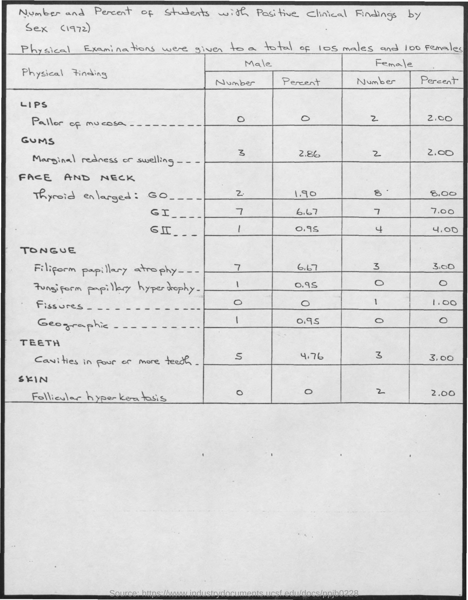

In [ ]:
doc_image.thumbnail((600, 600))
doc_image

In [ ]:
print(generate(doc_system_prompt, doc_question, doc_image))

To determine the number of females with "Cavities in four or more teeth," I'll follow these steps:

1. Locate the row for "TEETH" in the table.
2. Look at the column for "Female" under that row.
3. Find the value in that cell.

Step 1: The row for "TEETH" is visible in the table.

Step 2: The column for "Female" is the second column from the left.

Step 3: In the cell where the "TEETH" row intersects with the "Female" column, I see the value "3."

Therefore, there were 3 females who had "Cavities in four or more teeth."


### Document Understanding - Qwen

In [ ]:
doc_understanding_system_prompt = """
You are a multimodal document intelligence assistant specialized in OCR and
document understanding.

Your task is to carefully analyze the provided image of a document and
describe all the information that is visibly present in it.

First, perform OCR to accurately extract the text from the document. Then
understand the document's structure and layout and present its contents in a
clear, organized manner.

Include:
- All readable text, including headings, paragraphs, labels, names, dates,
  numbers, and other textual information.
- The structure and organization of the document.
- Tables, including their rows, columns, headers, and cell contents.
- Lists, forms, fields, and other structured information.
- Important visual relationships between different parts of the document.

Preserve the original information as accurately as possible, especially
names, numbers, dates, quantities, and monetary values.

Do not invent, infer, or assume information that is not visibly present in
the document. If some text is unclear or unreadable, explicitly indicate
that it is unclear or unreadable rather than guessing.

Provide a comprehensive description of the document's contents. Do not omit
readable information simply because it appears less important.
"""

https://huggingface.co/llava-hf/llava-v1.6-mistral-7b-hf

https://huggingface.co/llava-hf/llava-v1.6-vicuna-13b-hf

In [ ]:
def format_message_doc_understanding(system_prompt, image):

    messages = [
        {
            "role": "system",
            "content": system_prompt
        },
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image,
                }
            ],
        },
    ]
    return messages

In [ ]:
def generate(system_prompt, image):

    messages = format_message_doc_understanding(doc_understanding_system_prompt, image)

    # Preparation for inference.
    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt",
    )
    inputs = inputs.to(model.device)

    # Inference: Generation of the output.
    generated_ids = model.generate(**inputs, max_new_tokens=1024)
    generated_ids_trimmed = [
        out_ids[len(in_ids) :] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]
    output_text = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )
    return output_text[0]

#### Change Document & Generate Summary

In [ ]:
idx = 85
doc_image = docvqa_data['image'][idx]

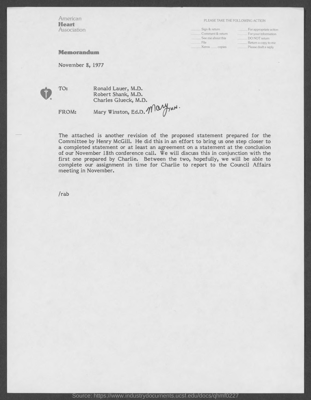

In [ ]:
doc_image.thumbnail((400, 400))
doc_image

In [ ]:
print(generate(doc_understanding_system_prompt, doc_image))

### Document Description

**Title:**
Memorandum

**Date:**
November 5, 1977

**To:**
Ronald Lauer, M.D.
Robert L. D., M.D.
Charles Gluck, M.D.

**From:**
Mary Winston, Ed.D.

---

**Body:**

The attached is another revision of the proposed statement prepared for the Committee by Henry McGill. He did this in an effort to bring us one step closer to a complete statement. We will discuss this in conjunction with the First Amendment by Charles Gluck. In the two, we should be able to complete our assignment in time for Committee Report to the Council Affairs meeting in November.

---

**Footer:**
/rab

---

**Structure and Organization:**

1. **Header:**
   - Title: Memorandum
   - Date: November 5, 1977

2. **Body:**
   - Addressed to three individuals: Ronald Lauer, M.D., Robert L. D., M.D., and Charles Gluck, M.D.
   - Signed by Mary Winston, Ed.D.
   - Content discusses the revision of a proposed statement prepared by Henry McGill for the Committee.
   - Mentions the First Amendment by 